# Stage 3: tyre model (part 1: setup and choice of settings)

This notebook builds the pace model that later gives each car's time-optimal pit lap. In this first part the model is set up, its settings are chosen on three example races, and the shared functions are put in `helpers.py`. Fitting all races comes in the next part.

**The model.** For each race, the time of a clean lap is

> lap time = driver baseline + lap-number effect × lap number + tyre curve of the compound (tyre age) + noise

- **Step A** (linear, per race): ordinary least squares with one dummy per driver, the lap number, one dummy per compound and one tyre-age slope per compound. It gives each driver's baseline and the lap-number effect in seconds per lap.
- **Step B** (Gaussian process, per race and compound): the driver baseline and the lap-number effect are subtracted, and the remaining lap time is fitted on tyre age. This gives a smooth wear curve that can bend, with its uncertainty.

**The lap-number effect** captures fuel burn and track evolution together: the car gets lighter and the track gets faster as rubber goes down. The two cannot be separated with these data and are not needed separately. Within a stint, lap number and tyre age both grow by one per lap, but tyre age starts again at a stop while the lap number keeps going, so with several stints per race the two effects can be told apart.

Input: `data/processed/laps.parquet` and `data/processed/races.parquet` (from stage 2). Output of this part: `results/lap_effect.csv`, `results/kernel_comparison.csv`, and three figures in `figures/`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel

from helpers import (DATA_PROCESSED, FIGURES, GP_RESTARTS, MAX_LAP_EFFECT_SE, MIN_COMPOUND_DRIVERS,
                     MIN_COMPOUND_LAPS, MIN_LENGTH_SCALE, RANDOM_SEED, RESULTS, fit_baseline_and_lap_effect,
                     fit_tyre_curve, predict_lap_time, predict_tyre_curve, sample_tyre_curves, tyre_kernel,
                     tyre_residual)

start_time = time.time()

# The three races used to choose the settings: high tyre wear, low tyre wear, and one from 2026.
EXAMPLE_RACES = {"2025 Sakhir (high wear)": (2025, "Sakhir"),
                 "2025 Monza (low wear)": (2025, "Monza"),
                 "2026 Hungaroring": (2026, "Hungaroring")}
# A lap-number effect outside this range (seconds per lap) is listed as implausible.
PLAUSIBLE_LAP_EFFECT = (-0.15, 0.0)
COMPOUNDS = ["SOFT", "MEDIUM", "HARD"]
COMPOUND_COLOURS = {"SOFT": "tab:red", "MEDIUM": "goldenrod", "HARD": "dimgray"}
RACE = ["year", "session_key", "circuit"]

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)

## 1. Usable laps

The pace model uses laps that are clean (`clean_lap`), not in traffic (`in_traffic` is False: no car within 2.0 s ahead on track) and from a dry race (`wet_race` is False). `tyre_age` already counts the laps a set did in earlier sessions.

In [2]:
laps = pd.read_parquet(DATA_PROCESSED / "laps.parquet")
races = pd.read_parquet(DATA_PROCESSED / "races.parquet")

usable = laps[laps["clean_lap"] & ~laps["in_traffic"] & ~laps["wet_race"]].copy()
assert usable["compound"].isin(COMPOUNDS).all() and usable["tyre_age"].notna().all()

print(f"laps: {len(laps):,} | usable: {len(usable):,} | dry races: {usable['session_key'].nunique()} of {len(races)}")

laps_per_race = (usable.pivot_table(index=RACE, columns="compound", values="lap_duration", aggfunc="size", fill_value=0)
                 .reindex(columns=COMPOUNDS))
laps_per_race["total"] = laps_per_race.sum(axis=1)
print("\nusable laps per compound, all dry races:", laps_per_race[COMPOUNDS].sum().to_dict())
print("\nusable laps per race, by season:")
print(laps_per_race.groupby("year")["total"].describe()[["count", "min", "50%", "max"]].astype(int).to_string())
print("\nusable laps per race and compound:")
print(laps_per_race.to_string())

laps: 101,930 | usable: 42,114 | dry races: 80 of 91

usable laps per compound, all dry races: {'SOFT': 5085, 'MEDIUM': 14276, 'HARD': 22753}

usable laps per race, by season:
      count  min  50%  max
year                      
2023     20  290  512  760
2024     21  357  539  767
2025     21  324  517  713
2026     18  233  519  752

usable laps per race and compound:
compound                             SOFT  MEDIUM  HARD  total
year session_key circuit                                      
2023 7779        Jeddah                14     134   295    443
     7787        Melbourne              4      40   296    340
     7953        Sakhir               195       7   358    560
     9070        Baku                   1      49   299    349
     9078        Miami                  0     127   461    588
     9102        Catalunya            174     233   316    723
     9110        Montreal               1     149   395    545
     9118        Spielberg              0     286   383    

## 2. Which compounds are fitted

A compound is fitted in a race only if it has at least 30 usable laps from at least 3 drivers (`MIN_COMPOUND_LAPS`, `MIN_COMPOUND_DRIVERS` in `helpers.py`). With fewer laps, or laps from one or two cars, the curve would describe those cars and not the tyre. The rule is applied before step A as well: a compound with a single lap cannot give both a level and a slope.

Skipped compounds stay in the table below with the reason. Their laps are not used by the tyre model.

In [3]:
cells = (usable.groupby(RACE + ["compound"])
         .agg(laps=("lap_duration", "size"), drivers=("driver_number", "nunique"), oldest_tyre=("tyre_age", "max"))
         .reset_index())
cells["reason_skipped"] = ""
cells.loc[cells["drivers"] < MIN_COMPOUND_DRIVERS, "reason_skipped"] = f"fewer than {MIN_COMPOUND_DRIVERS} drivers"
# The lap rule is written last, so a compound that fails both rules is counted under the lap rule.
cells.loc[cells["laps"] < MIN_COMPOUND_LAPS, "reason_skipped"] = f"fewer than {MIN_COMPOUND_LAPS} laps"
cells["fitted"] = cells["reason_skipped"] == ""

skipped = cells[~cells["fitted"]]
print(f"race x compound cells: {len(cells)} | fitted: {int(cells['fitted'].sum())} | skipped: {len(skipped)}")
print(skipped.groupby("reason_skipped").agg(cells=("laps", "size"), laps=("laps", "sum")).to_string())
print(f"usable laps in skipped cells: {int(skipped['laps'].sum())} of {len(usable)} ({skipped['laps'].sum() / len(usable):.1%})")
driver_rule_only = skipped[skipped["laps"] >= MIN_COMPOUND_LAPS]
print(f"skipped cells that also have fewer than {MIN_COMPOUND_DRIVERS} drivers: "
      f"{int((skipped['drivers'] < MIN_COMPOUND_DRIVERS).sum())} of {len(skipped)}")
print(f"extra cells removed by the driver rule ({MIN_COMPOUND_LAPS} laps or more, fewer than {MIN_COMPOUND_DRIVERS} drivers): "
      f"{len(driver_rule_only)}")
if len(driver_rule_only) > 0:
    print(driver_rule_only.to_string(index=False))
print("\nfitted compounds per race:", cells[cells["fitted"]].groupby("session_key").size().value_counts().sort_index().to_dict())

model_laps = usable.merge(cells.loc[cells["fitted"], ["session_key", "compound"]], on=["session_key", "compound"])
print("laps used by the tyre model:", len(model_laps))

race x compound cells: 217 | fitted: 181 | skipped: 36
                    cells  laps
reason_skipped                 
fewer than 30 laps     36   379
usable laps in skipped cells: 379 of 42114 (0.9%)
skipped cells that also have fewer than 3 drivers: 26 of 36
extra cells removed by the driver rule (30 laps or more, fewer than 3 drivers): 0

fitted compounds per race: {2: 59, 3: 21}
laps used by the tyre model: 41735


## 3. Step A for every dry race: driver baselines and the lap-number effect

Step A is fitted separately for each dry race. The two races with laps missing at the source (2023 Monza, 2025 Miami) are fitted on the laps they have and keep their flag `race_missing_laps`.

**Imprecise races.** The lap-number effect can only be separated from tyre wear when drivers have more than one usable stint. A race whose estimate has a standard error above 0.01 s per lap (`MAX_LAP_EFFECT_SE`) uses the median of the other races of its season instead; its driver baselines are then fitted again with the lap-number effect fixed at that value.

In [4]:
rows = []
step_a = {}
for (year, session_key, circuit), race_laps in model_laps.groupby(RACE):
    fit = fit_baseline_and_lap_effect(race_laps)
    step_a[session_key] = fit
    rows.append({"year": year, "session_key": session_key, "circuit": circuit, "usable_laps": fit["laps"],
                 "drivers": race_laps["driver_number"].nunique(),
                 "lap_effect_own": fit["lap_effect"], "lap_effect_se": fit["lap_effect_se"],
                 "full_rank": fit["full_rank"]})
lap_effects = pd.DataFrame(rows)
assert lap_effects["full_rank"].all()

# Races that are too imprecise take the median of the precise races of the same season.
lap_effects["pooled"] = lap_effects["lap_effect_se"] > MAX_LAP_EFFECT_SE
season_median = lap_effects[~lap_effects["pooled"]].groupby("year")["lap_effect_own"].median()
lap_effects["lap_effect"] = lap_effects["lap_effect_own"].where(~lap_effects["pooled"],
                                                               lap_effects["year"].map(season_median))
for race in lap_effects[lap_effects["pooled"]].itertuples():
    race_laps = model_laps[model_laps["session_key"] == race.session_key]
    step_a[race.session_key] = fit_baseline_and_lap_effect(race_laps, fixed_lap_effect=race.lap_effect)

lap_effects = lap_effects.merge(races[["session_key", "race_missing_laps"]], on="session_key")
lap_effects = lap_effects.drop(columns="full_rank")

print("LAP-NUMBER EFFECT PER RACE (seconds per lap; negative = laps get faster during the race)")
print(lap_effects.round(4).to_string(index=False))

LAP-NUMBER EFFECT PER RACE (seconds per lap; negative = laps get faster during the race)
 year  session_key            circuit  usable_laps  drivers  lap_effect_own  lap_effect_se  pooled  lap_effect  race_missing_laps
 2023         7779             Jeddah          429       20         -0.0662         0.0047   False     -0.0662                  0
 2023         7787          Melbourne          336       18         -0.0733         0.0427    True     -0.0532                  0
 2023         7953             Sakhir          553       20         -0.0682         0.0018   False     -0.0682                  0
 2023         9070               Baku          348       18         -0.0745         0.0067   False     -0.0745                  0
 2023         9078              Miami          588       20         -0.0472         0.0016   False     -0.0472                  0
 2023         9102          Catalunya          723       20         -0.0532         0.0013   False     -0.0532                  0
 

In [5]:
own = lap_effects["lap_effect_own"]
print("distribution over the", len(lap_effects), "dry races (each race's own estimate):")
print(own.describe().round(4).to_string())

print("\nby season:")
print(lap_effects.groupby("year")["lap_effect_own"].describe().round(4).to_string())

is_2026 = lap_effects["year"] == 2026
early, late = own[~is_2026], own[is_2026]
difference = late.mean() - early.mean()
difference_se = np.sqrt(early.var() / len(early) + late.var() / len(late))
print(f"\n2023-2025: mean {early.mean():.4f}, median {early.median():.4f} ({len(early)} races) | "
      f"2026: mean {late.mean():.4f}, median {late.median():.4f} ({len(late)} races)")
print(f"difference 2026 minus 2023-2025: {difference:.4f} s per lap (standard error {difference_se:.4f})")

implausible = lap_effects[(own > PLAUSIBLE_LAP_EFFECT[1]) | (own < PLAUSIBLE_LAP_EFFECT[0])]
print(f"\nraces with an implausible estimate (positive, or faster than {-PLAUSIBLE_LAP_EFFECT[0]} s per lap): {len(implausible)}")
print("\nthe five largest and five smallest effects:")
print(pd.concat([lap_effects.nsmallest(5, "lap_effect_own"), lap_effects.nlargest(5, "lap_effect_own")])
      [["year", "circuit", "usable_laps", "lap_effect_own", "lap_effect_se"]].round(4).to_string(index=False))
print(f"\nstandard error: median {lap_effects['lap_effect_se'].median():.4f}, "
      f"90% of races below {lap_effects['lap_effect_se'].quantile(0.9):.4f}")
print(f"\nraces using the season median (standard error above {MAX_LAP_EFFECT_SE}):")
print(lap_effects[lap_effects["pooled"]].round(4).to_string(index=False))

RESULTS.mkdir(parents=True, exist_ok=True)
lap_effects.to_csv(RESULTS / "lap_effect.csv", index=False)
print(f"\nsaved results/lap_effect.csv: {len(lap_effects)} rows")

distribution over the 80 dry races (each race's own estimate):
count    80.0000
mean     -0.0562
std       0.0197
min      -0.1274
25%      -0.0668
50%      -0.0555
75%      -0.0415
max      -0.0119

by season:
      count    mean     std     min     25%     50%     75%     max
year                                                               
2023   20.0 -0.0573  0.0159 -0.0865 -0.0692 -0.0559 -0.0457 -0.0330
2024   21.0 -0.0662  0.0255 -0.1274 -0.0803 -0.0658 -0.0469 -0.0274
2025   21.0 -0.0534  0.0139 -0.0790 -0.0599 -0.0556 -0.0415 -0.0323
2026   18.0 -0.0467  0.0176 -0.0752 -0.0602 -0.0499 -0.0362 -0.0119

2023-2025: mean -0.0590, median -0.0568 (62 races) | 2026: mean -0.0467, median -0.0499 (18 races)
difference 2026 minus 2023-2025: 0.0123 s per lap (standard error 0.0048)

races with an implausible estimate (positive, or faster than 0.15 s per lap): 0

the five largest and five smallest effects:
 year           circuit  usable_laps  lap_effect_own  lap_effect_se
 2024       M

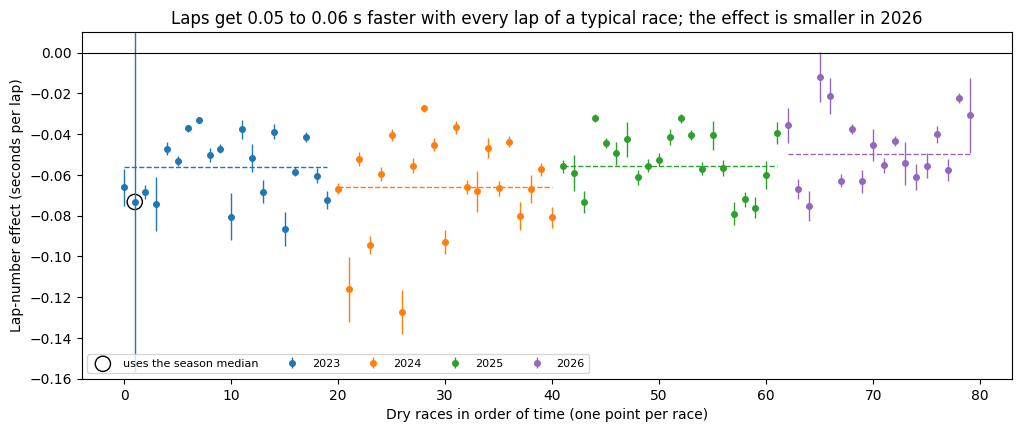

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
season_colours = {2023: "tab:blue", 2024: "tab:orange", 2025: "tab:green", 2026: "tab:purple"}
position = np.arange(len(lap_effects))
for year, colour in season_colours.items():
    season = (lap_effects["year"] == year).to_numpy()
    # Error bars are cut at the edge of the plot for the one race that is far too imprecise.
    ax.errorbar(position[season], lap_effects.loc[season, "lap_effect_own"], yerr=1.96 * lap_effects.loc[season, "lap_effect_se"],
                fmt="o", markersize=4, color=colour, elinewidth=1, label=str(year))
    ax.hlines(lap_effects.loc[season, "lap_effect_own"].median(), position[season].min(), position[season].max(),
              color=colour, linestyle="--", linewidth=1)
pooled = lap_effects["pooled"].to_numpy()
ax.scatter(position[pooled], lap_effects.loc[pooled, "lap_effect_own"], s=120, facecolors="none", edgecolors="black",
           label="uses the season median")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-0.16, 0.01)
ax.set_xlabel("Dry races in order of time (one point per race)")
ax.set_ylabel("Lap-number effect (seconds per lap)")
ax.set_title("Laps get 0.05 to 0.06 s faster with every lap of a typical race; the effect is smaller in 2026")
ax.legend(ncol=5, fontsize=8, loc="lower left")
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "lap_effect_by_race.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure: lap-number effect per race.** Each point is one dry race with its 95% interval; dashed lines are season medians. Look at: every race is below zero (laps get faster as fuel burns off and the track rubbers in), the 2026 points sit higher than the earlier seasons, and the circled race has an interval so wide that it runs out of the plot, which is why it uses the season median.

## 4. Three kernels compared on three example races

Step B needs a kernel, which says how smooth the tyre curve may be. Three candidates are compared on a high-wear race (2025 Sakhir), a low-wear race (2025 Monza) and a 2026 race (2026 Hungaroring):

1. RBF + WhiteKernel: a smooth curve plus lap-to-lap noise;
2. Matern(nu=1.5) + WhiteKernel: a rougher curve plus noise;
3. RBF + DotProduct + WhiteKernel: a smooth curve plus a straight wear trend plus noise.

Each smooth and linear part is multiplied by a constant, so its size is estimated and not fixed at 1. In all three kernels the length scale is at least 5 laps of tyre age (`MIN_LENGTH_SCALE`): shorter length scales fitted bumps in the noise. The optimizer is started again from 3 random points with `RANDOM_SEED`.

Two measures are used:

- **log marginal likelihood**: how well the kernel explains the laps, with a built-in penalty for flexibility (higher is better). It is computed on the residual scaled to standard deviation 1, which is the same for the three kernels of a compound, so values are comparable between kernels but not between races.
- **held-out error**: each driver in turn is left out, the Gaussian process is fitted on the other drivers, and the left-out driver's laps are predicted (root mean squared error in seconds, lower is better). Step A is fitted once on all drivers; only the Gaussian process is refitted without the held-out driver. The held-out driver's baseline is therefore known, and the error measures how well the tyre curve carries over to a car it has not seen.

This cell refits the Gaussian process once per driver, compound and kernel, and takes most of the notebook's runtime.

In [7]:
def candidate_kernels():
    "Return the three kernels that are compared (new objects on every call)."
    amplitude = ConstantKernel(1.0, (1e-3, 1e3))
    noise = WhiteKernel(0.5, (1e-3, 1e1))
    return {
        "RBF + White": amplitude * RBF(10.0, (MIN_LENGTH_SCALE, 200.0)) + noise,
        "Matern(1.5) + White": amplitude * Matern(10.0, (MIN_LENGTH_SCALE, 200.0), nu=1.5) + noise,
        "RBF + DotProduct + White": tyre_kernel(),
    }


def held_out_errors(tyre_age, residual, driver, kernel_name):
    "Leave each driver out in turn; return the errors on that driver's laps (s) and how many refits had a parameter at a bound."
    errors = []
    refits_at_bound = 0
    for held_out in np.unique(driver):
        train = driver != held_out
        curve = fit_tyre_curve(tyre_age[train], residual[train], candidate_kernels()[kernel_name])
        predicted, _ = predict_tyre_curve(curve, tyre_age[~train])
        errors.append(residual[~train] - predicted)
        refits_at_bound += curve["parameters_at_bound"] != ""
    return np.concatenate(errors), refits_at_bound


example_keys = {name: int(races.loc[(races["year"] == year) & (races["circuit"] == circuit), "session_key"].iloc[0])
                for name, (year, circuit) in EXAMPLE_RACES.items()}

comparison_start = time.time()
example_laps = {}
kernel_fits = {}
rows = []
for race_name, session_key in example_keys.items():
    race_laps = model_laps[model_laps["session_key"] == session_key].copy()
    lap_effect = lap_effects.loc[lap_effects["session_key"] == session_key, "lap_effect"].iloc[0]
    race_laps["residual"] = tyre_residual(race_laps, step_a[session_key]["baseline"], lap_effect)
    example_laps[race_name] = race_laps
    for compound, compound_laps in race_laps.groupby("compound"):
        tyre_age = compound_laps["tyre_age"].to_numpy(float)
        residual = compound_laps["residual"].to_numpy(float)
        driver = compound_laps["driver_number"].to_numpy()
        for kernel_name, kernel in candidate_kernels().items():
            curve = fit_tyre_curve(tyre_age, residual, kernel)
            errors, refits_at_bound = held_out_errors(tyre_age, residual, driver, kernel_name)
            kernel_fits[(race_name, compound, kernel_name)] = curve
            rows.append({"race": race_name, "compound": compound, "kernel": kernel_name, "laps": len(residual),
                         "drivers": len(np.unique(driver)),
                         "log_marginal_likelihood": curve["gp"].log_marginal_likelihood_value_,
                         "squared_error": float(errors @ errors),
                         "held_out_rmse": float(np.sqrt(np.mean(errors ** 2))),
                         "length_scale_at_bound": curve["length_scale_at_bound"],
                         "parameters_at_bound": curve["parameters_at_bound"],
                         "held_out_refits": len(np.unique(driver)), "refits_at_bound": refits_at_bound,
                         "fitted_kernel": str(curve["gp"].kernel_)})
kernel_detail = pd.DataFrame(rows)
print(f"kernel comparison: {time.time() - comparison_start:.0f} s")

kernel comparison: 339 s


In [8]:
def summarise(group):
    "Add up the likelihood and pool the held-out errors over the compounds of a group."
    return pd.Series({"compounds": len(group), "laps": group["laps"].sum(),
                      "log_marginal_likelihood": group["log_marginal_likelihood"].sum(),
                      "held_out_rmse": np.sqrt(group["squared_error"].sum() / group["laps"].sum())})


per_race = kernel_detail.groupby(["race", "kernel"], sort=False)[kernel_detail.columns].apply(summarise).reset_index()
overall = kernel_detail.groupby("kernel", sort=False)[kernel_detail.columns].apply(summarise).reset_index()
overall.insert(0, "race", "all three races")
kernel_table = pd.concat([per_race, overall], ignore_index=True)
kernel_table[["compounds", "laps"]] = kernel_table[["compounds", "laps"]].astype(int)
kernel_table[["log_marginal_likelihood", "held_out_rmse"]] = kernel_table[["log_marginal_likelihood", "held_out_rmse"]].round(3)
kernel_table.to_csv(RESULTS / "kernel_comparison.csv", index=False)

print("KERNEL COMPARISON (results/kernel_comparison.csv)")
print(kernel_table.to_string(index=False))
print("\nper compound:")
pd.set_option("display.max_colwidth", 120)
print(kernel_detail.drop(columns=["squared_error"]).round(3).to_string(index=False))

KERNEL COMPARISON (results/kernel_comparison.csv)
                   race                   kernel  compounds  laps  log_marginal_likelihood  held_out_rmse
2025 Sakhir (high wear)              RBF + White          3   383                 -239.679          0.425
2025 Sakhir (high wear)      Matern(1.5) + White          3   383                 -239.533          0.410
2025 Sakhir (high wear) RBF + DotProduct + White          3   383                 -235.214          0.420
  2025 Monza (low wear)              RBF + White          2   468                 -595.584          0.300
  2025 Monza (low wear)      Matern(1.5) + White          2   468                 -596.285          0.300
  2025 Monza (low wear) RBF + DotProduct + White          2   468                 -594.583          0.300
       2026 Hungaroring              RBF + White          3   752                 -687.905          0.599
       2026 Hungaroring      Matern(1.5) + White          3   752                 -687.523          0.

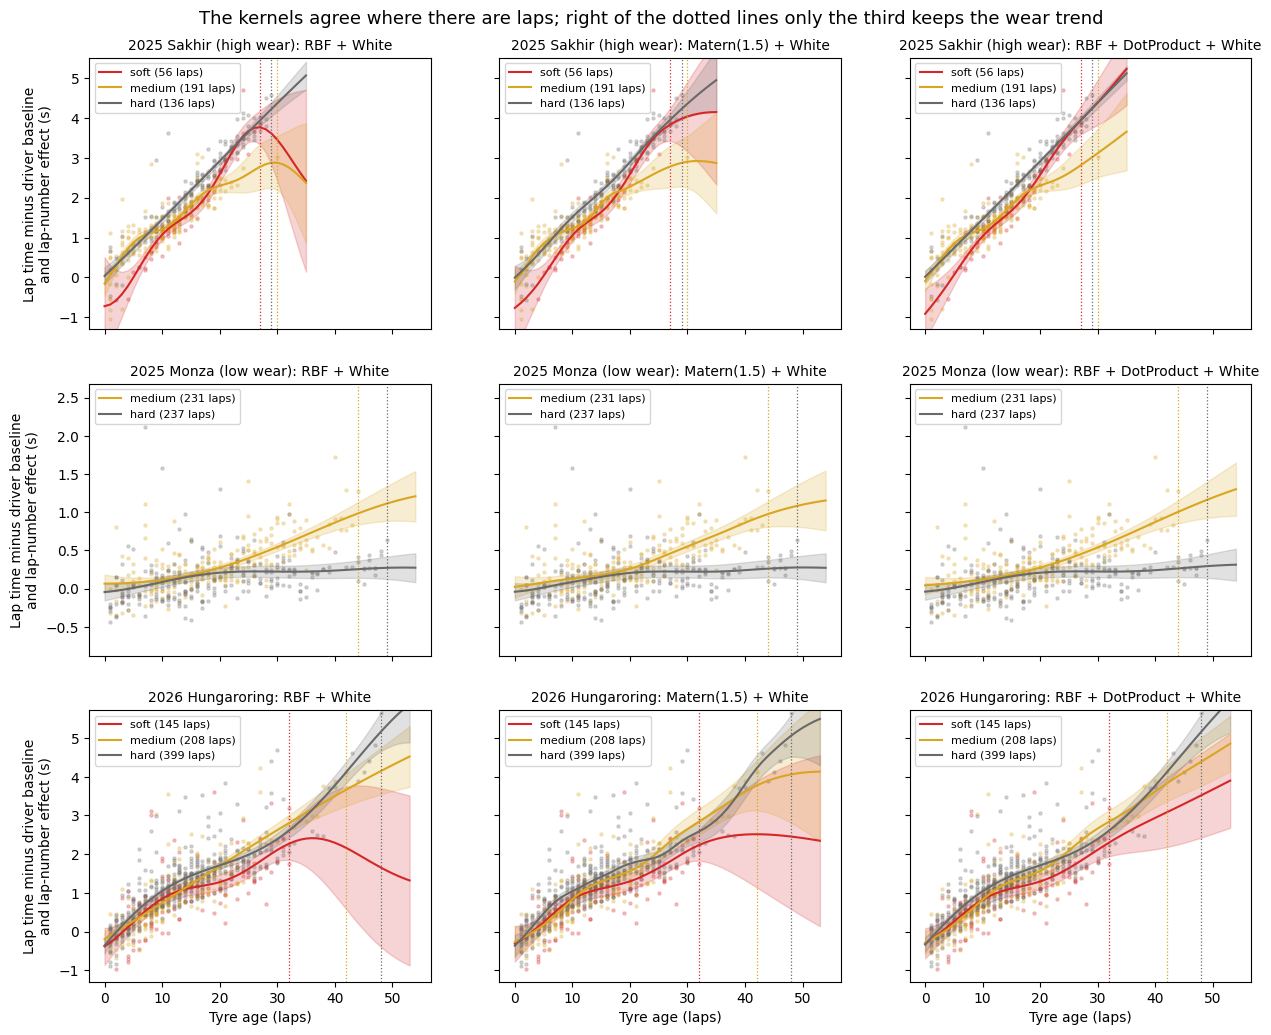

In [9]:
def plot_curve(ax, curve, compound_laps, compound, grid):
    "Draw the laps of one compound, its fitted curve and the 95% band of the curve."
    colour = COMPOUND_COLOURS[compound]
    mean, sd = predict_tyre_curve(curve, grid)
    ax.scatter(compound_laps["tyre_age"], compound_laps["residual"], s=5, alpha=0.25, color=colour)
    ax.plot(grid, mean, color=colour, label=f"{compound.lower()} ({len(compound_laps)} laps)")
    ax.fill_between(grid, mean - 1.96 * sd, mean + 1.96 * sd, color=colour, alpha=0.2)
    # The dotted line marks the oldest tyre observed: to its right the curve is an extrapolation.
    ax.axvline(compound_laps["tyre_age"].max(), color=colour, linestyle=":", linewidth=0.9)


kernel_names = list(candidate_kernels())
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True, sharey="row")
for row, (race_name, race_laps) in enumerate(example_laps.items()):
    grid = np.arange(0, race_laps["tyre_age"].max() + 6)
    for column, kernel_name in enumerate(kernel_names):
        ax = axes[row, column]
        for compound in [c for c in COMPOUNDS if c in set(race_laps["compound"])]:
            plot_curve(ax, kernel_fits[(race_name, compound, kernel_name)], race_laps[race_laps["compound"] == compound],
                       compound, grid)
        ax.set_ylim(race_laps["residual"].quantile(0.005) - 0.5, race_laps["residual"].quantile(0.995) + 1.0)
        ax.set_title(f"{race_name}: {kernel_name}", fontsize=10)
        ax.legend(fontsize=8, loc="upper left")
        if column == 0:
            ax.set_ylabel("Lap time minus driver baseline\nand lap-number effect (s)")
        if row == 2:
            ax.set_xlabel("Tyre age (laps)")
fig.suptitle("The kernels agree where there are laps; right of the dotted lines only the third keeps the wear trend",
             fontsize=13, y=0.92)
fig.savefig(FIGURES / "kernel_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure: three kernels on three races.** Points are usable laps after removing the driver baseline and the lap-number effect; lines are the fitted tyre curves, shaded areas the 95% band of the curve itself (without lap-to-lap noise); the dotted vertical lines mark the oldest tyre observed for each compound. Look at: within the data the three columns are almost the same; to the right of the dotted lines the curves in the first two columns flatten or fall back towards the average, while in the third column they keep rising with the wear trend.

**Choice.** The tyre curve uses the third kernel: constant × RBF (length scale at least 5 laps) + constant × DotProduct + WhiteKernel. Inside the data the three kernels agree; this one has the best likelihood in each of the three races and the best held-out error over the three races together (table above; at Sakhir alone Matern has a slightly lower held-out error, at Monza the three are equal), and it continues the wear trend beyond the oldest observed tyre. This matters for the next part, where the model is asked what a stint would have cost if it had been longer than any stint actually driven. The kernel and its settings are in `tyre_kernel` in `helpers.py`.

## 5. Final fits for the three example races

The same three races, now fitted with the shared functions of `helpers.py` exactly as later stages will use them:

- `fit_baseline_and_lap_effect` (step A) and `fit_tyre_curve` (step B);
- `fit_tyre_curve` filters only the scikit-learn warnings saying that a kernel parameter is close to one of its bounds, and records them instead: the column `parameters_at_bound` lists them for every fit (`length_scale_at_bound` says whether the RBF length scale is at its minimum of 5 laps). A parameter at its bound means that this part of the kernel was not needed in that fit, for example a straight wear line instead of a bend when the amplitude of the RBF part is at its lower bound. Any other warning, such as an optimizer that does not converge, is still shown;
- `predict_tyre_curve` and `predict_lap_time` return the mean and the standard deviation of the curve **without** lap-to-lap noise. scikit-learn's own standard deviation includes the WhiteKernel noise, which describes a single lap and not the curve; the functions take it off;
- `sample_tyre_curves` draws whole curves without noise. The next part uses such draws for the interval around the optimal pit lap.

In [10]:
final_curves = {}
rows = []
for race_name, race_laps in example_laps.items():
    session_key = example_keys[race_name]
    for compound in [c for c in COMPOUNDS if c in set(race_laps["compound"])]:
        compound_laps = race_laps[race_laps["compound"] == compound]
        curve = fit_tyre_curve(compound_laps["tyre_age"], compound_laps["residual"])
        final_curves[(race_name, compound)] = curve
        oldest = int(compound_laps["tyre_age"].max())
        mean, sd = predict_tyre_curve(curve, [1, oldest])
        _, sd_with_noise = curve["gp"].predict(np.array([[oldest / 2]]), return_std=True)
        _, sd_middle = predict_tyre_curve(curve, [oldest / 2])
        rows.append({"race": race_name, "compound": compound, "laps": len(compound_laps),
                     "drivers": compound_laps["driver_number"].nunique(), "oldest_tyre": oldest,
                     "new_tyre_level": mean[0], "level_at_oldest": mean[1],
                     "rise_per_lap": (mean[1] - mean[0]) / (oldest - 1),
                     "step_a_slope": step_a[session_key]["wear"][compound],
                     "curve_sd_mid_stint": sd_middle[0],
                     "sd_with_noise_mid_stint": sd_with_noise[0] * curve["scale"],
                     "length_scale": curve["length_scale"],
                     "length_scale_at_bound": curve["length_scale_at_bound"],
                     "parameters_at_bound": curve["parameters_at_bound"]})
final_table = pd.DataFrame(rows)
print("FINAL FITS (seconds; levels are relative to the driver baseline, at tyre age 1 and at the oldest tyre observed)")
print(final_table.round(3).to_string(index=False))

FINAL FITS (seconds; levels are relative to the driver baseline, at tyre age 1 and at the oldest tyre observed)
                   race compound  laps  drivers  oldest_tyre  new_tyre_level  level_at_oldest  rise_per_lap  step_a_slope  curve_sd_mid_stint  sd_with_noise_mid_stint  length_scale  length_scale_at_bound      parameters_at_bound
2025 Sakhir (high wear)     SOFT    56        9           27          -0.737            3.931         0.180         0.167               0.069                    0.331         5.000                   True rbf_length_scale (lower)
2025 Sakhir (high wear)   MEDIUM   191       15           30           0.103            3.114         0.104         0.107               0.053                    0.388         5.000                   True rbf_length_scale (lower)
2025 Sakhir (high wear)     HARD   136       14           29           0.159            4.232         0.145         0.146               0.032                    0.354       141.822                  Fal

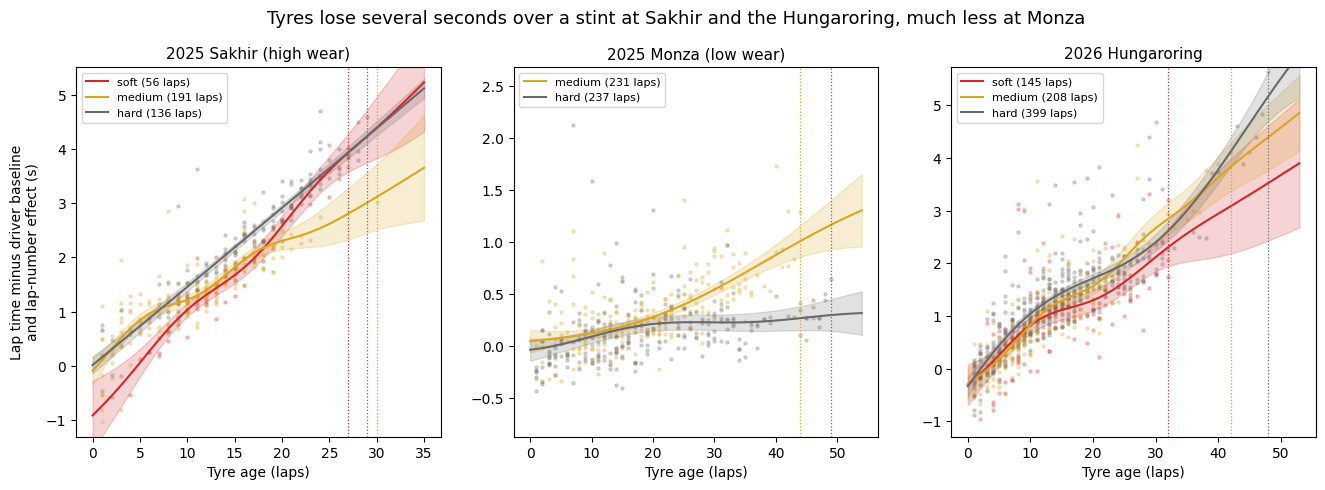

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (race_name, race_laps) in zip(axes, example_laps.items()):
    grid = np.arange(0, race_laps["tyre_age"].max() + 6)
    for compound in [c for c in COMPOUNDS if c in set(race_laps["compound"])]:
        plot_curve(ax, final_curves[(race_name, compound)], race_laps[race_laps["compound"] == compound], compound, grid)
    ax.set_ylim(race_laps["residual"].quantile(0.005) - 0.5, race_laps["residual"].quantile(0.995) + 1.0)
    ax.set_title(race_name, fontsize=11)
    ax.set_xlabel("Tyre age (laps)")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Lap time minus driver baseline\nand lap-number effect (s)")
fig.suptitle("Tyres lose several seconds over a stint at Sakhir and the Hungaroring, much less at Monza", fontsize=13, y=1.0)
fig.savefig(FIGURES / "tyre_curves_examples.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure: fitted tyre curves of the three example races.** Points are usable laps after removing the driver baseline and the lap-number effect; lines are the fitted curves with the 95% band of the curve itself; dotted lines mark the oldest tyre observed. Look at: how steeply each curve rises (the wear), where each compound starts at the left (its pace when new), and how the band widens where there are few laps.

In [12]:
# How the shared functions are used: the lap time of one car on a given lap and tyre age, and draws of the curve.
race_name, compound = "2025 Sakhir (high wear)", "HARD"
session_key = example_keys[race_name]
curve = final_curves[(race_name, compound)]
baseline = step_a[session_key]["baseline"]
lap_effect = lap_effects.loc[lap_effects["session_key"] == session_key, "lap_effect"].iloc[0]
driver = baseline.index[0]
tyre_age = np.array([1, 10, 20, 30])
lap_time, lap_time_sd = predict_lap_time(curve, baseline[driver], lap_effect, lap_number=20 + tyre_age, tyre_age=tyre_age)
print(f"{race_name}, car {driver}, {compound.lower()} tyres fitted at the end of lap 20:")
print(pd.DataFrame({"tyre_age": tyre_age, "lap_number": 20 + tyre_age, "lap_time": lap_time.round(3),
                    "sd_of_curve": lap_time_sd.round(3)}).to_string(index=False))

draws = sample_tyre_curves(curve, tyre_age, n_samples=2000)
same_draws = sample_tyre_curves(curve, tyre_age, n_samples=2000)
_, curve_sd = predict_tyre_curve(curve, tyre_age)
print("\n2000 draws of the curve: standard deviation per tyre age", draws.std(axis=0).round(3),
      "| from predict_tyre_curve:", curve_sd.round(3))
print("the same seed gives the same draws:", bool(np.array_equal(draws, same_draws)))

2025 Sakhir (high wear), car 1, hard tyres fitted at the end of lap 20:
 tyre_age  lap_number  lap_time  sd_of_curve
        1          21    97.543        0.075
       10          30    98.158        0.042
       20          40    98.852        0.034
       30          50    99.559        0.067

2000 draws of the curve: standard deviation per tyre age [0.075 0.042 0.034 0.069] | from predict_tyre_curve: [0.075 0.042 0.034 0.067]
the same seed gives the same draws: True


## 6. Checks

Are the example curves plausible? Lap time should rise with tyre age, and a softer compound should be faster when new.

In [13]:
# 1. Every lap of the model belongs to a fitted compound, and no lap is used twice.
assert not model_laps.duplicated(["session_key", "driver_number", "lap_number"]).any()
assert len(model_laps) == cells.loc[cells["fitted"], "laps"].sum()
print(f"1. laps in the model: {len(model_laps)} = usable laps {len(usable)} minus {len(usable) - len(model_laps)} in skipped compounds")

# 2. Step A could be solved in every race, and every race has a lap-number effect.
assert lap_effects["lap_effect"].notna().all() and len(lap_effects) == usable["session_key"].nunique()
print(f"2. step A fitted for {len(lap_effects)} dry races; lap-number effect between {lap_effects['lap_effect'].min():.4f} "
      f"and {lap_effects['lap_effect'].max():.4f} s per lap; races using the season median: {int(lap_effects['pooled'].sum())}")

# 3. Lap time rises with tyre age in every example curve.
print("3. curves that rise from a new tyre to the oldest tyre observed:",
      int((final_table["rise_per_lap"] > 0).sum()), "of", len(final_table))

# 4. Softer compounds are faster when new (level at tyre age 1, seconds relative to the driver baseline).
new_levels = final_table.pivot(index="race", columns="compound", values="new_tyre_level").reindex(
    index=list(EXAMPLE_RACES), columns=COMPOUNDS)
print("4. level of a new tyre (tyre age 1):")
print(new_levels.round(3).to_string())

# 5. The band of the curve is narrower than scikit-learn's band, which includes the lap-to-lap noise.
assert (final_table["curve_sd_mid_stint"] < final_table["sd_with_noise_mid_stint"]).all()
print("5. the curve's standard deviation is below the one with noise in all", len(final_table), "fits")

# 6. How often a kernel parameter stopped at a bound (that part of the kernel was not needed in the fit).
print(f"6. fits with the length scale at its lower bound of {MIN_LENGTH_SCALE:.0f} laps: final fits "
      f"{int(final_table['length_scale_at_bound'].sum())} of {len(final_table)} | kernel comparison "
      f"{int(kernel_detail['length_scale_at_bound'].sum())} of {len(kernel_detail)}")
print(f"   fits with any parameter at a bound: final fits {int((final_table['parameters_at_bound'] != '').sum())} of "
      f"{len(final_table)} | kernel comparison {int((kernel_detail['parameters_at_bound'] != '').sum())} of {len(kernel_detail)} | "
      f"held-out refits of the comparison {int(kernel_detail['refits_at_bound'].sum())} of {int(kernel_detail['held_out_refits'].sum())}")
print("   held-out refits with a parameter at a bound, per kernel:")
print(kernel_detail.groupby("kernel", sort=False)[["held_out_refits", "refits_at_bound"]].sum().to_string())
print("   which parameters, final fits:", final_table.loc[final_table["parameters_at_bound"] != "", "parameters_at_bound"].value_counts().to_dict())
print("   which parameters, kernel comparison:", kernel_detail.loc[kernel_detail["parameters_at_bound"] != "", "parameters_at_bound"].value_counts().to_dict())

1. laps in the model: 41735 = usable laps 42114 minus 379 in skipped compounds
2. step A fitted for 80 dry races; lap-number effect between -0.1274 and -0.0119 s per lap; races using the season median: 1
3. curves that rise from a new tyre to the oldest tyre observed: 8 of 8
4. level of a new tyre (tyre age 1):
compound                  SOFT  MEDIUM   HARD
race                                         
2025 Sakhir (high wear) -0.737   0.103  0.159
2025 Monza (low wear)      NaN   0.049 -0.031
2026 Hungaroring        -0.205  -0.203 -0.168
5. the curve's standard deviation is below the one with noise in all 8 fits
6. fits with the length scale at its lower bound of 5 laps: final fits 3 of 8 | kernel comparison 3 of 24
   fits with any parameter at a bound: final fits 3 of 8 | kernel comparison 3 of 24 | held-out refits of the comparison 51 of 336
   held-out refits with a parameter at a bound, per kernel:
                          held_out_refits  refits_at_bound
kernel                   

**Reading the checks.**

- All example curves rise with tyre age. The rise is steep at Sakhir, moderate at the Hungaroring and small at Monza (close to zero for the hard tyre), as expected for a high-wear, a medium-wear and a low-wear circuit.
- At Sakhir the order of the new tyres is as expected: the soft is clearly the fastest and the medium is slightly faster than the hard. At the Hungaroring the three compounds start at almost the same level, and at Monza the new medium is slightly slower than the new hard, so the expected order does not show there. The level of a compound is the least certain part of the model: it is identified only by drivers who used both compounds in the race, and teams choose the compound to suit the car, the fuel load and the moment of the race, so the laps on each compound are not a random sample. The later stages use the curves to compare pit laps of the same car on the compounds it actually used, where the shape of the curve matters more than the gap between compounds; the uncertain levels are a limit to keep in mind when two compounds are compared directly.

## 7. Report

In [14]:
print("USABLE LAPS")
print(f"usable laps: {len(usable)} in {usable['session_key'].nunique()} dry races | per compound: {laps_per_race[COMPOUNDS].sum().to_dict()}")
print(f"race x compound cells: {len(cells)} | fitted: {int(cells['fitted'].sum())} | skipped: {len(skipped)} "
      f"({skipped['reason_skipped'].value_counts().to_dict()}) | laps in the model: {len(model_laps)}")

print("\nLAP-NUMBER EFFECT (seconds per lap, results/lap_effect.csv)")
summary = lap_effects.assign(season=lap_effects["year"].astype(str)).groupby("season")["lap_effect_own"].describe()
summary.loc["all"] = own.describe()
summary.loc["2023-2025"] = early.describe()
print(summary[["count", "mean", "std", "min", "50%", "max"]].round(4).to_string())
print(f"difference 2026 minus 2023-2025: {difference:.4f} (standard error {difference_se:.4f}) | implausible: {len(implausible)} | "
      f"season median used: {lap_effects.loc[lap_effects['pooled'], ['year', 'circuit']].astype(str).agg(' '.join, axis=1).tolist()}")

print("\nKERNEL COMPARISON (results/kernel_comparison.csv)")
print(kernel_table.to_string(index=False))

print("\nFINAL FITS OF THE EXAMPLE RACES")
print(final_table[["race", "compound", "laps", "drivers", "oldest_tyre", "new_tyre_level", "rise_per_lap",
                   "curve_sd_mid_stint", "length_scale", "parameters_at_bound"]].round(3).to_string(index=False))

print(f"\nsettings: at least {MIN_COMPOUND_LAPS} laps and {MIN_COMPOUND_DRIVERS} drivers per compound | season median above a standard "
      f"error of {MAX_LAP_EFFECT_SE} | length scale at least {MIN_LENGTH_SCALE:.0f} laps | {GP_RESTARTS} optimizer restarts | seed {RANDOM_SEED}")
print(f"figures: lap_effect_by_race.png, kernel_comparison.png, tyre_curves_examples.png")
print(f"runtime: {time.time() - start_time:.0f} s")

USABLE LAPS
usable laps: 42114 in 80 dry races | per compound: {'SOFT': 5085, 'MEDIUM': 14276, 'HARD': 22753}
race x compound cells: 217 | fitted: 181 | skipped: 36 ({'fewer than 30 laps': 36}) | laps in the model: 41735

LAP-NUMBER EFFECT (seconds per lap, results/lap_effect.csv)
           count    mean     std     min     50%     max
season                                                  
2023        20.0 -0.0573  0.0159 -0.0865 -0.0559 -0.0330
2024        21.0 -0.0662  0.0255 -0.1274 -0.0658 -0.0274
2025        21.0 -0.0534  0.0139 -0.0790 -0.0556 -0.0323
2026        18.0 -0.0467  0.0176 -0.0752 -0.0499 -0.0119
all         80.0 -0.0562  0.0197 -0.1274 -0.0555 -0.0119
2023-2025   62.0 -0.0590  0.0196 -0.1274 -0.0568 -0.0274
difference 2026 minus 2023-2025: 0.0123 (standard error 0.0048) | implausible: 0 | season median used: ['2023 Melbourne']

KERNEL COMPARISON (results/kernel_comparison.csv)
                   race                   kernel  compounds  laps  log_marginal_likelihoo